# Predicting Anthocyanin Content from Colour Features
**Submitted By:** Mary Anne Selirio

**Course:** Applied Analytics & AI (TX00GM35)
**Date:** October 2026

**Thesis Connection:** This notebook represents the method-development phase for my Master's Thesis on authenticating Philippine Ube (*Dioscorea alata*). It tests whether smartphone colorimetry can reliably predict anthocyanin pigment, and more importantly, how severely *capture session conditions* (lighting, day) bias the model.

**Repository:** github.com/marysel-metropolia/anthocyanin-analysis · **Data:** Navarro et al. (2022), GigaDB doi:10.5524/102220 (CC0); camera curves: Jiang et al. (2013), Zenodo 3245883 (CC BY-NC-SA 4.0).

**Use of AI Tools:** In line with Metropolia guidelines, I used AI assistants (Claude; Gemini in Colab) for ideation, code drafting, debugging and text refinement. I checked all the numbers agains the notebook output and all sources against the original publications.


## How this notebook follows the recommended course flow: (9 steps)
| Course step | Report section | Notebook part |
|---|---|---|
| 1 Industrial problem | 1 Project Overview and Scope; 2.1 Problem Statement | Report only |
| 2 Objective | 1 (Objective); 2.2 Research Questions | Report only |
| 3 KPIs | 2.2 Table 1 (targets); 6 Table 5 (results) | Part G · KPI check |
| 4 Data | 3 Data and Preparation, Table 2 | Part A · Data Ingestion & Preparation: Load and check data |
| 5 Exploratory Analysis | 4 Exploratory Analysis, Figures 1-3 | Part B · Exploratory analysis |
| 6 Analytics / AI workflow | 5 Method / Workflow, Figure 4, Table 3 | Part C · Workflow; Part D · Main model (linear regression) |
| 7 Evaluation | 6 Results, Tables 4-5, Figures 5-6; 7 Discussion and Interpretation | Part D · Main model; Part E · Diagnostics; Part F · Robustness check; Part G · KPI check |
| 8 Governance, Privacy, Security | 8 Governance, Privacy, and Security, Table 7 | Report only |
| 9 Outputs | 9 Conclusion; 9.1 Project Status, Table 8 | Part H · Project status |

The first setup cell below establishes a reproducible, robust environment (using a fixed SEED = 42) and imports the necessary tools to address the data's specific challenges. Standard machine learning estimators (LinearRegression, RandomForest, and HistGradientBoosting) are imported alongside preprocessing pipelines (StandardScaler and make_pipeline) to safely evaluate predictive power. Crucially, the inclusion of PLSRegression and variance_inflation_factor (VIF) prepares the workflow to handle the high multicollinearity inherent in 37 spectral bands, while unsupervised tools (KMeans, PCA, and ARI metrics) are imported to diagnose underlying environmental grouping and ensure the model is learning actual chemical pigment signals rather than capture-session artifacts.

In [ ]:
import os, warnings, urllib.request; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.cross_decomposition import PLSRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor, RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.model_selection import (train_test_split, KFold, LeaveOneGroupOut, GroupKFold, GridSearchCV,
                                     cross_val_predict, cross_val_score, StratifiedKFold)
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, silhouette_score, adjusted_rand_score

SEED = 42
OUT = "outputs"; os.makedirs(OUT, exist_ok=True)
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#e4e3df", "axes.axisbelow": True,
                     "axes.titleweight": "bold"})
pd.set_option("display.precision", 3)

## Part A. Data Ingestion & Preparation: Load and Check the Data (Report Section 3.1-3.3, Table 2)




**Objective:** Load the proxy multispectral grape dataset (Navarro et al., 2022) and simulate smartphone RGB camera channels.

The dataset contains multispectral imaging (MSI) data. The range of 37 bands comes directly from the original publication by Navarro et al. (2022). Their instrument captured 37 different narrow bands of light (from visible to near-infrared). There are 5 varieties of grape berries: Itum4, Itum5, Crimson, AutumRoyal, and Itum9 in the source experiment, they are listed in ORDER to ensure plots always show them in logical progression (usually from green/light varieties with low pigment to deep purple/dark varieties with high pigment).

In [ ]:
GH = "https://raw.githubusercontent.com/marysel-metropolia/anthocyanin-analysis/refs/heads/main/"
gt = pd.read_csv(GH + "groundTruth.csv")
sp = pd.read_csv(GH + "MSI_spectral-spatialCompressed.csv")
sp = sp.rename(columns={sp.columns[0]: "ArrayName"})
df = gt.merge(sp, on="ArrayName", validate="one_to_one")          # error if any berry ID repeats
df = df.rename(columns={"Anthocyanines.mg.kgFW.": "TAC", "Type": "variety", "Measure": "session"})
BANDS = [f"Channel{i}" for i in range(1, 38)]
ORDER = ["Itum4", "Itum5", "Crimson", "AutumRoyal", "Itum9"]
VCOL = dict(zip(ORDER, PAL))
y, day = df.TAC.values, df.session.values

print("Grape Berries:", len(df), "| Missing Values:", int(df.isna().sum().sum()), "| Photo Sessions:", df.session.nunique())
print(df.variety.value_counts()[ORDER].to_dict())

Grape Berries: 1283 | Missing Values: 0 | Photo Sessions: 13
{'Itum4': 84, 'Itum5': 504, 'Crimson': 401, 'AutumRoyal': 199, 'Itum9': 95}


**Observation:** The dataset contains 1,283 grape samples ("berries") across 5 distinct varieties, tracked across 13 different photo sessions, with 37 spectral band measurements and ground-truth anthocyanin pigment levels (TAC). There are 0 missing values which means that the data is clean and the IDs merge perfectly. However, a major hidden challenge is that each photo session only contains one variety of grape, meaning variety and photo day are completely confounded. It is learning to identify which photo session a grape came from, the ML modell is not actually learning the relationship between grape color and pigment.

**Interpretation:** The dataset is highly clean with 1,283 samples and zero missing values, providing a solid foundation of spectral and chemical measurements across five varieties. However, because each photo session contains only a single variety, there is a perfect confounding between variety and capture session that may lead models to learn session-specific lighting fingerprints rather than true pigment relationships.


**Photo Sessions:** This refers to 13 separate photo sessions (or photo days). Instead of taking all photos under identical conditions, the grapes were photographed across 13 distinct setups or days.

In [ ]:
wl = np.array([488.38, 488.58, 503.59, 516.60, 530.62, 542.17, 567.96, 579.29, 592.89, 602.88, 616.59, 625.71])  # Navarro et al. 2022, Table 2
cam_wl = np.arange(400, 721, 10)
R = [0.0005826,0.0015345,0.0032648,0.0017968,0.0011327,0.0010138,0.0012358,0.0015814,0.0023156,0.0033231,0.0099827,0.019719,0.052282,0.11518,0.12991,0.10525,0.14334,0.28241,0.31153,0.55747,0.5377,0.49413,0.42527,0.36399,0.27563,0.21406,0.14996,0.068701,0.012535,0.0023522,0.00050291,0.00013838,4.4186e-05]
G = [0.0022632,0.0090549,0.040708,0.047983,0.069255,0.098384,0.11977,0.16981,0.31083,0.46114,0.94734,0.83935,0.89683,1,0.92794,0.87725,0.74845,0.63893,0.33715,0.32125,0.1676,0.082557,0.043512,0.029175,0.019359,0.013462,0.010043,0.0062015,0.0016749,0.00044468,0.00013311,3.9683e-05,1.7053e-05]
B = [0.010972,0.08325,0.41186,0.57035,0.71985,0.76168,0.8411,0.82581,0.78355,0.62952,0.68337,0.30674,0.14434,0.072663,0.041467,0.022853,0.010411,0.0064022,0.0032002,0.0032854,0.0022498,0.0014714,0.0012154,0.0011413,0.0013655,0.0017246,0.0019172,0.0011647,0.00023847,5.004e-05,1.6586e-05,9.5302e-06,8.494e-06]

S = np.vstack([np.interp(wl, cam_wl, c) for c in (R, G, B)])
def to_rgb(V, S): return V @ S.T / S.sum(axis=1)
df[["R", "G", "B"]] = to_rgb(df[BANDS[:12]].values, S)
RGB = ["R", "G", "B"]
df.groupby("variety")[RGB].mean().loc[ORDER].round(2)

,R,G,B
variety,,,
Itum4,21.51,20.23,16.27
Itum5,48.21,41.76,33.56
Crimson,37.15,29.65,25.54
AutumRoyal,22.75,25.61,26.06
Itum9,24.69,28.71,30.03


**Observation:** Three broad camera colors can stand in for the 37 bands because they key pigment (anthocyanin) absorbs light heavily within the visible spectrum, and neighboring bands are highly redundant. However, converting to RGB discards fine spectral details (smoothing sharp absorption peaks) and completely loses the near-infrared band data (channels 13-38) which are invisble to standard camera sensors.

**Interpretation:**

**Simulated camera RGB** (Table 2): the 12 visible bands weighted by the Canon 1D Mark III sensitivity curves (Jiang et al., 2013), interpolated to the exact band wavelengths in Table 2 of Navarro et al. (2022). This is a *colorimetric proxy for spectral analysis*, not real phone photos.

## Part B · Exploratory Analysis (Report Section 4)
### B1 · Distribution and Group Differences (Section 4.1)

**Objective:** Check data distributions and identify confounding variables.

**Hypothesis:** Pigment variation is mostly between different varieties (green vs. purple), and capture sessions might act as a confounder.

In [ ]:
desc = df.groupby("variety").TAC.agg(["count", "mean", "median", "std"]).loc[ORDER]
print(desc.round(2))
print(f"\nAll grape berries: mean {df.TAC.mean():.1f}, median {df.TAC.median():.1f} mg/kg, skewness {df.TAC.skew():.1f}")
print(f"Shapiro–Wilk p = {stats.shapiro(df.TAC).pvalue:.1e}")
groups = [df.loc[df.variety == v, "TAC"] for v in ORDER]
print("Kruskal–Wallis H = %.0f, p = %.1e" % stats.kruskal(*groups))
print("Levene p = %.1e" % stats.levene(*groups).pvalue)

            count   mean  median    std
variety                                
Itum4          84   0.11    0.07   0.16
Itum5         504   0.26    0.20   0.23
Crimson       401   2.39    1.58   2.60
AutumRoyal    199  21.80   19.86  15.24
Itum9          95  32.94   30.30  18.33

All grape berries: mean 6.7, median 0.7 mg/kg, skewness 2.9
Shapiro–Wilk p = 1.2e-48
Kruskal–Wallis H = 1043, p = 1.7e-224
Levene p = 1.3e-163


**Observation:**
Count shows unbalanced dataset with 504 grapes
of Itum5 vs only 84 of Itum4. This will create bias toward teh patterns in the dominant varieties. There is a right-skewed distribution. This means the overwhelming majority of grapes contain no pigment (0 to 1 mg/kg), while a small handful of purple grapes have exceptionally high pigment levels. The Std is extremely low for green grapes meaning they are uniformlly low in pigment. The Std for purple grapes is massive, indicating wide variation.


*   Count: groups are unbalanced (84 to 504 berries).

*   Mean vs median: for all berries, the mean is 6.7 and the median 0.7. A few very purple berries pull the mean up, which makes the distribution right-skewed.


*   Std: tiny for the green varieties, large for the purple ones (15–18).
*   Shapiro–Wilk p ≈ 0: the pigment values are clearly not normal.
*   Kruskal–Wallis H = 1,043, p ≈ 0: the varieties differ strongly in pigment.
*   Levene p ≈ 0: the spread differs between varieties.
*   For the regression: most of what the model can explain is green vs purple, so a high R² can come from telling the colours apart, not from measuring the amount. Expect larger errors on purple berries and some negative predictions for green ones. Section 6 confirms this (purple berries predicted at only 13–24, 427 green berries below zero).

**Interpretation:** Most berries have almost no pigment... so the model mainly green vs. purple.

### B2 · Figure 1: anthocyanin per berry by variety

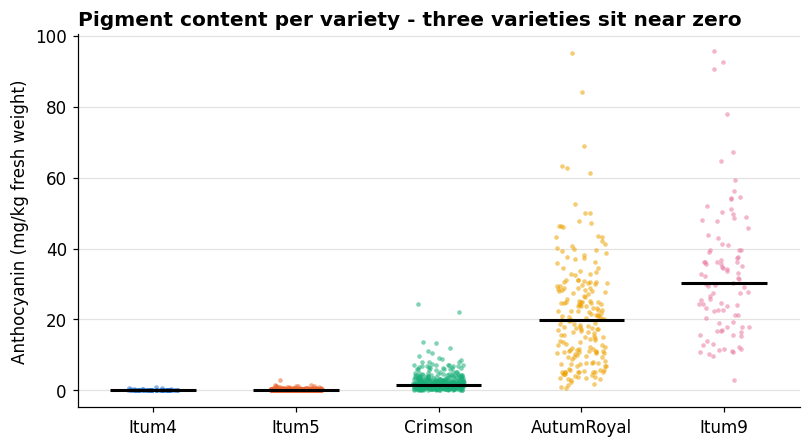

In [ ]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for i, v in enumerate(ORDER):
    vals = df.loc[df.variety == v, "TAC"].values
    jit = np.random.default_rng(SEED).uniform(-0.18, 0.18, len(vals))
    ax.scatter(np.full(len(vals), i) + jit, vals, s=9, color=VCOL[v], alpha=0.55, linewidths=0)
    ax.hlines(np.median(vals), i - 0.3, i + 0.3, color="k", lw=2)
ax.set_xticks(range(5), ORDER); ax.grid(axis="x", visible=False)
ax.set_ylabel("Anthocyanin (mg/kg fresh weight)")
ax.set_title("Pigment content per variety - three varieties sit near zero", loc="left")
fig.tight_layout(); fig.savefig(f"{OUT}/fig1_tac_by_variety.png"); plt.show()

**Observation:** Based on the distribution shown, the vast majority of the variation in pigment content (anthocyanin) is driven by the differences between the varieties rather than withind individual varieties. Specifically, the green grape varieties (Itum4, Itum5, and Crimson) exhibit almost not variation as their values cluster tightly near zero, while the purple varieties (AutumRoyal and Itum9) contribute nearly all of the spread and variance.

**Interpretation:** Most of the variation in anthocyanin comes from the fundamental genetic differences between green varieties (which consistently stay near zero) and purple varieties, combined with a high degree of natural, continouous biological variation within the purple grape varieties (AutumRoyal and Itum9).

### B3 · Outliers and confounding (→ Sections 4.2, 4.3)

In [ ]:
def iqr_out(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return int(((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).sum())
print("IQR outliers, pooled:", iqr_out(df.TAC), "| within each variety:", sum(iqr_out(g) for g in groups))
pd.crosstab(df.session, df.variety)[ORDER]      # each session holds one variety only

IQR outliers, pooled: 233 | within each variety: 75


variety,Itum4,Itum5,Crimson,AutumRoyal,Itum9
session,,,,,
Autumn Royal 1 November,0,0,0,98,0
Autumn Royal 2 November,0,0,0,101,0
Crimson December,0,0,101,0,0
Crimson November,0,0,102,0,0
Crimson October,0,0,100,0,0
Crimson September,0,0,98,0,0
Itum 4 September,84,0,0,0,0
Itum 5 December 1,0,101,0,0,0
Itum 5 December 2,0,99,0,0,0


**Observation:** 233 pooled outliers but only 75 within varieties; each session holds one variety.

**Interpretation:** Outliers were not removed because they represent genuine biological diversity across varieties, and discarding them would mask the true spectral characterisiics of high-pigment grapes. Having only one variety per session is a major problem because variety and session are perfectly confounded, meaning a model might simply memoreize the lighting or background fingerprint of a specific photo sesion rather than learning actual biochemical pigment relationships.

### B4 · Correlation, Figure 2, and Multicollinearity (Sections 4.4, 4.5)

In [ ]:
r_band = df[BANDS].corrwith(df.TAC)
print(f"Strongest band: {r_band.abs().idxmax()} (626 nm), pooled r = {r_band[r_band.abs().idxmax()]:.2f}")
print("Within each variety:", {v: round(stats.pearsonr(df.loc[df.variety == v, 'Channel12'], df.loc[df.variety == v, 'TAC'])[0], 2) for v in ORDER})
print("p-values within variety:", {v: round(stats.pearsonr(df.loc[df.variety == v, 'Channel12'], df.loc[df.variety == v, 'TAC'])[1], 3) for v in ORDER})
print("Neighbouring bands, Channel1 vs Channel2: r =", round(df.Channel1.corr(df.Channel2), 3))

def vif(cols):
    X = sm.add_constant(df[cols].values)
    return np.array([variance_inflation_factor(X, i) for i in range(1, X.shape[1])])
v37, vrgb = vif(BANDS), vif(RGB)
print(f"VIF 37 bands: {v37.min():.0f} to {v37.max():.1e} | VIF R, G, B: {vrgb.min():.0f} to {vrgb.max():.0f}")

Strongest band: Channel12 (626 nm), pooled r = -0.54
Within each variety: {'Itum4': np.float64(-0.12), 'Itum5': np.float64(-0.03), 'Crimson': np.float64(-0.02), 'AutumRoyal': np.float64(-0.11), 'Itum9': np.float64(0.04)}
p-values within variety: {'Itum4': np.float64(0.272), 'Itum5': np.float64(0.574), 'Crimson': np.float64(0.644), 'AutumRoyal': np.float64(0.117), 'Itum9': np.float64(0.669)}
Neighbouring bands, Channel1 vs Channel2: r = 1.0
VIF 37 bands: 44 to 2.9e+09 | VIF R, G, B: 24 to 96


**Observation:** Pooled r = −0.54 at 626 nm, but |r| ≤ 0.12 inside each variety; VIF very high.

**Interpretation:** This is a classic example of Simpson's Paradox: the strong pooled correlation is driven entirey by the macro-level differences between the highly pigmented purple varieties and low-pigmented green varieities. Inside any single variety, the linear relationship between pigment and wavelength reflection disappears, meaning the model is distinguising between teh broad groups rather than tracking continuous biochemical variations within them.

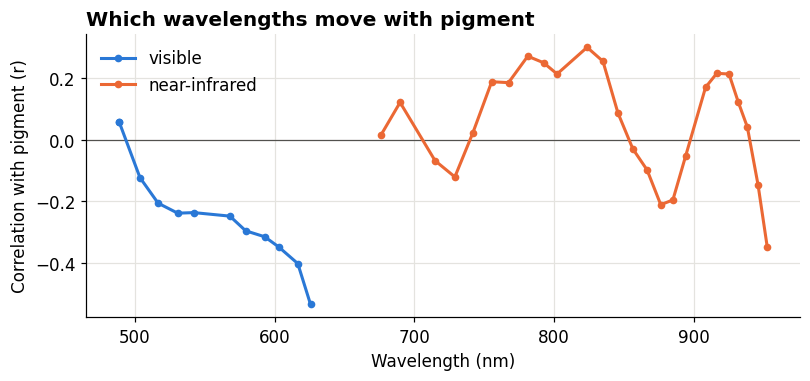

In [ ]:
# Figure 2: correlation of each band with anthocyanin (pooled). Band wavelengths from Navarro et al. (2022), Table 2.
WL = np.array([488.38, 488.58, 503.59, 516.60, 530.62, 542.17, 567.96, 579.29, 592.89, 602.88, 616.59, 625.71,
               676.25, 689.83, 714.87, 729.06, 741.80, 755.44, 767.48, 781.25, 792.57, 802.25, 823.75, 835.10,
               845.81, 856.52, 866.68, 876.49, 885.18, 894.26, 908.58, 916.63, 925.36, 931.99, 938.48, 946.14, 952.76])
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.axhline(0, color="#52514e", lw=0.8)
ax.plot(WL[:12], r_band.values[:12], color=PAL[0], lw=2, marker="o", ms=4, label="visible")
ax.plot(WL[12:], r_band.values[12:], color=PAL[1], lw=2, marker="o", ms=4, label="near-infrared")
ax.set_xlabel("Wavelength (nm)"); ax.set_ylabel("Correlation with pigment (r)")
ax.set_title("Which wavelengths move with pigment", loc="left"); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(f"{OUT}/fig2_band_correlation.png"); plt.show()

**Observation:** The useful signal is in a standard, consumer-grade camera sensor can capture the necessary colour changes without requiring specialized or expensive near-infrared hardware.

**Interpretation:** This is highly promising for a smartphone-based application because the strongest correlation with anthocyanin pigment lies entirely within the visible wavelength range (400-700 nm). Consequently, a standard, consumer-grade camera sensor can capture the necessary spectral changes without requiring specialized or expensive near-infrared hardware.

### B5 · Clusters and Figure 3: PCA (Section 4.6)
K-means on the standardised 37 bands; variety, session and TAC are **not** used.

Silhouette range K = 2–15: 0.37 to 0.48
K = 13: ARI with session = 0.74 | ARI with variety = 0.26
PC1 + PC2 explain 82 % of variance


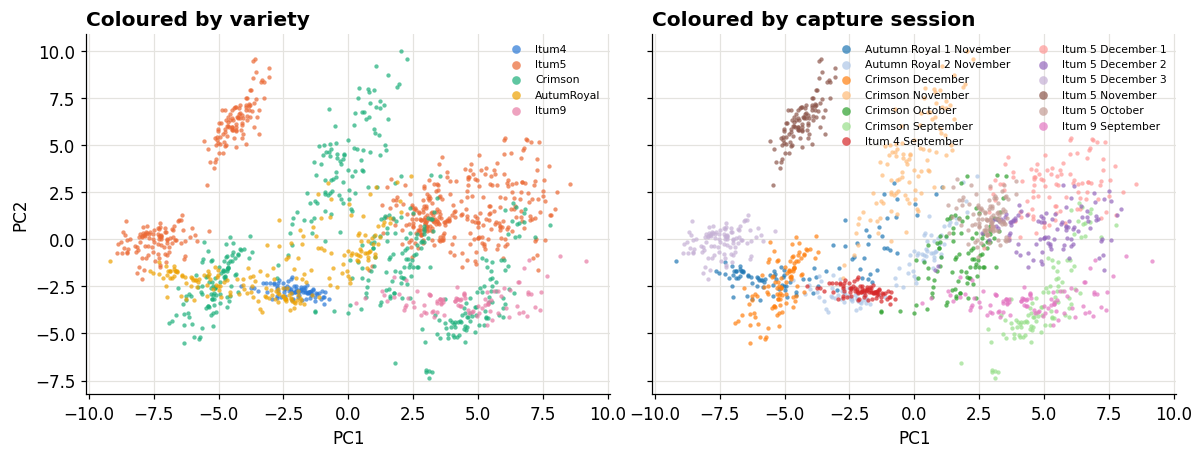

In [ ]:
Z = StandardScaler().fit_transform(df[BANDS])
sil = {k: silhouette_score(Z, KMeans(k, n_init=10, random_state=SEED).fit_predict(Z)) for k in range(2, 16)}
print("Silhouette range K = 2–15: %.2f to %.2f" % (min(sil.values()), max(sil.values())))
km13 = KMeans(13, n_init=10, random_state=SEED).fit_predict(Z)
print(f"K = 13: ARI with session = {adjusted_rand_score(day, km13):.2f} | ARI with variety = {adjusted_rand_score(df.variety, km13):.2f}")

pca = PCA(2, random_state=SEED).fit(Z); pcs = pca.transform(Z)
print(f"PC1 + PC2 explain {100 * pca.explained_variance_ratio_.sum():.0f} % of variance")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), sharey=True)
for ax, col, title in [(axes[0], "variety", "Coloured by variety"), (axes[1], "session", "Coloured by capture session")]:
    cats = ORDER if col == "variety" else sorted(df[col].unique())
    for i, c in enumerate(cats):
        m = (df[col] == c).values
        ax.scatter(pcs[m, 0], pcs[m, 1], s=8, alpha=0.7, linewidths=0, label=c,
                   color=VCOL[c] if col == "variety" else plt.cm.tab20.colors[i % 20])
    ax.set_title(title, loc="left"); ax.set_xlabel("PC1")
    ax.legend(frameon=False, fontsize=7, markerscale=2, ncol=1 if len(cats) <= 8 else 2)
axes[0].set_ylabel("PC2")
fig.tight_layout(); fig.savefig(f"{OUT}/fig3_pca_variety_session.png"); plt.show()

**Observation:** Clusters agree with photo session (ARI 0.74) far more than variety (0.26). One variety splits into islands.

**Interpretation:** The unsupervised clustering is primarily detecing the technical, enviornmental fingerprints of individual photo sessions (such as lighting variations, setup calibration, or ambient conditions) rather than geniune biological variety or pigment differences. This is critical for model validation because it warns us that a standard random split will allow the model to cheat by memozirzing session-specific artifacts instead of learning actual chemical features, making a leave-one-sesion-out test essential.

## Part C · Figure 4: workflow (Report Section 5)

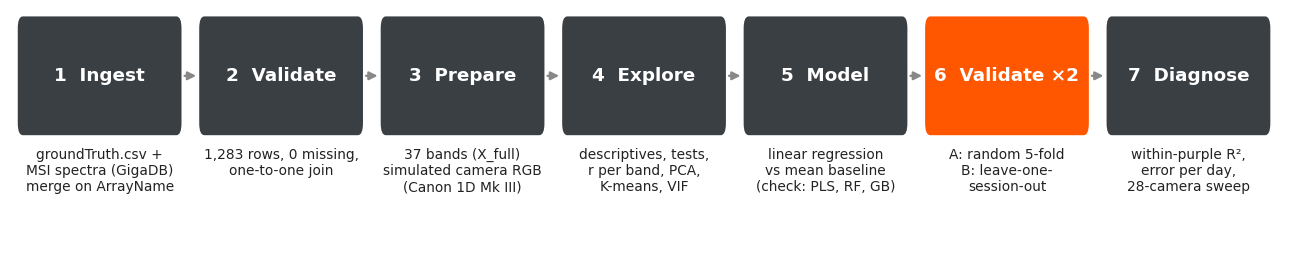

In [ ]:
from matplotlib.patches import FancyBboxPatch
steps=[("1  Ingest","groundTruth.csv +\nMSI spectra (GigaDB)\nmerge on ArrayName"),
("2  Validate","1,283 rows, 0 missing,\none-to-one join"),
("3  Prepare","37 bands (X_full)\nsimulated camera RGB\n(Canon 1D Mk III)"),
("4  Explore","descriptives, tests,\nr per band, PCA,\nK-means, VIF"),
("5  Model","linear regression\nvs mean baseline\n(check: PLS, RF, GB)"),
("6  Validate ×2","A: random 5-fold\nB: leave-one-\nsession-out"),
("7  Diagnose","within-purple R²,\nerror per day,\n28-camera sweep")]
fig,ax=plt.subplots(figsize=(15,2.9));ax.axis('off');w=1.9;g=0.25
for i,(t,d) in enumerate(steps):
    x=i*(w+g)
    c="#FF5600" if i==5 else "#3A3F44"
    ax.add_patch(FancyBboxPatch((x,0),w,0.55,boxstyle="round,pad=0.02,rounding_size=0.06",fc=c,ec="none"))
    ax.text(x+w/2,0.275,t,ha='center',va='center',color='white',fontsize=12,weight='bold')
    ax.text(x+w/2,-0.08,d,ha='center',va='top',fontsize=9,color="#222")
    if i<len(steps)-1: ax.annotate("",xy=(x+w+g-0.02,0.275),xytext=(x+w+0.02,0.275),arrowprops=dict(arrowstyle="-|>",color="#888",lw=1.5))
ax.set_xlim(-0.1,len(steps)*(w+g));ax.set_ylim(-0.62,0.6)
plt.savefig(f"{OUT}/fig0_workflow.png", dpi=200, bbox_inches="tight"); plt.show()

The seven steps from the data to diagnosis.

Step 6 Validate x2 is the most important step for my thesis because it reveals whether our colorimetric predictions are actually learning chemical properties or simply memorizing session-specific artificats. Designing an unseen-day validation (leave-one-session-out) is critical to ensuring that a model deployed on a smartphone app will generalize robustly to new users, lighting conditions, and days.

## Part D · Main model: multiple linear regression (Report Section 6, Table 4, Figure 5)
- **Test A · random:** random 5-fold (five 80/20 hold-outs); test berries share photo days with training berries.
- **Test B · new session:** each of the 13 sessions is held out once (leave-one-session-out).

In [ ]:
def metrics(yt, p): return {"R2": r2_score(yt, p), "MAE": mean_absolute_error(yt, p), "RMSE": mean_squared_error(yt, p) ** 0.5}
lin = lambda: make_pipeline(StandardScaler(), LinearRegression())
CV = {"A random": KFold(5, shuffle=True, random_state=SEED), "B new session": LeaveOneGroupOut()}

rows, preds = [], {}
for fname, cols in [("Camera RGB", RGB), ("37 bands", BANDS)]:
    for test, cv in CV.items():
        p = cross_val_predict(lin(), df[cols].values, y, cv=cv, groups=day)
        preds[(fname, test)] = p
        rows.append({"features": fname, "model": "Linear regression", "test": test, **metrics(y, p)})
for test, cv in CV.items():   # mean baseline: predict the training-set mean
    p = cross_val_predict(lin(), np.zeros((len(y), 1)), y, cv=cv, groups=day)
    rows.append({"features": "–", "model": "Mean baseline", "test": test, **metrics(y, p)})
table4 = pd.DataFrame(rows).pivot_table(index=["features", "model"], columns="test", values=["R2", "MAE"])
print("Table 4 (report shows R² for A and B, and MAE for B):"); table4.round(2)

Table 4 (report shows R² for A and B, and MAE for B):


MAE                     R2              
test                         A random B new session A random B new session
features   model                                                          
37 bands   Linear regression     4.07         10.82     0.62         -0.62
Camera RGB Linear regression     6.05          7.00     0.49          0.39
–          Mean baseline         8.83          9.47    -0.00         -0.11

**Observation:** RGB: 0.49 → 0.39; 37 bands: 0.62 → −0.62; baseline MAE 9.47.

**Interpretation:** When evaluated on an unseen photo session, the performance of the 37-band model collapses completely (R² drops to −0.62) because it overfits to high-dimensional, session-specific lighting artificats. In contrast, the simpler Camera RGB feature set holds upp much better (retaining an R² of 0.39), demonstrating that lower-dimensional colorimetric data is far more robust against domain shifts.

In [ ]:
# Table 4 caption: single 20 % hold-out, the wine-exercise design
tr, te = train_test_split(np.arange(len(y)), test_size=0.2, random_state=SEED)
for fname, cols in [("RGB", RGB), ("37 bands", BANDS)]:
    m = lin().fit(df.loc[tr, cols], y[tr])
    print(f"20 % hold-out R², {fname}: {r2_score(y[te], m.predict(df.loc[te, cols])):.2f}")

20 % hold-out R², RGB: 0.45
20 % hold-out R², 37 bands: 0.58


**Observation:** A single 20 % hold-out looks good: 0.45(RGB), 0.58 (37 bands).

**Interpretation:** A random hold-out is not enough because it allows berries from the same photo session to be split between the training and test sets, leaking session-specific lighting and setup characteristics. This leads to artifically high validation scores that fail to reflect how the model will perform on completely new days or environments.

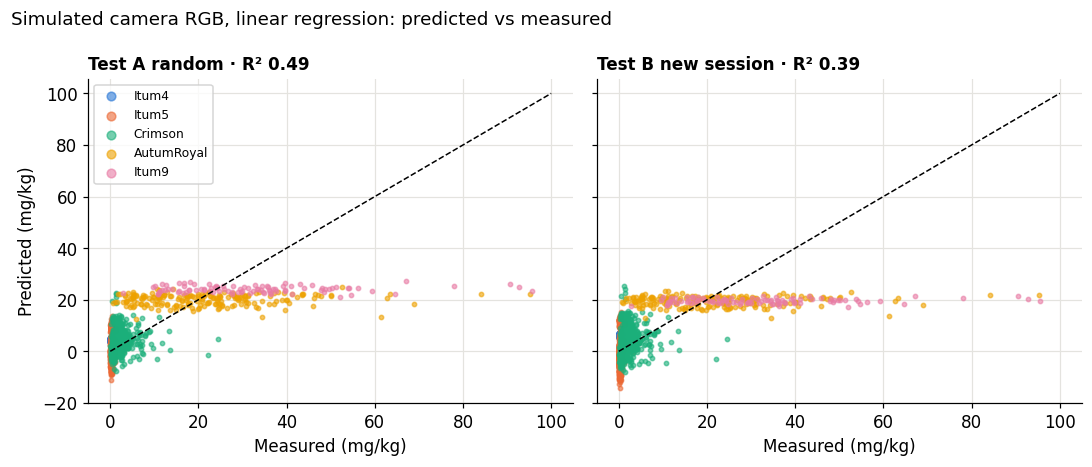

In [ ]:
# Figure 5: RGB linear regression, predicted vs measured
fig, axes = plt.subplots(1, 2, figsize=(10, 4.3), sharey=True)
for ax, test in zip(axes, CV):
    p = preds[("Camera RGB", test)]
    for v in ORDER:
        k = (df.variety == v).values
        ax.scatter(y[k], p[k], s=8, alpha=.6, color=VCOL[v], label=v)
    ax.plot([0, 100], [0, 100], "k--", lw=1)
    ax.set_title(f"Test {test} · R² {r2_score(y, p):.2f}", loc="left", fontsize=11); ax.set_xlabel("Measured (mg/kg)")
axes[0].set_ylabel("Predicted (mg/kg)"); axes[0].legend(fontsize=8, markerscale=2)
fig.suptitle("Simulated camera RGB, linear regression: predicted vs measured", x=0.01, ha="left", fontsize=12)
fig.tight_layout(); fig.savefig(f"{OUT}/fig5_pred_vs_measured_linear.png"); plt.show()

**Observation:** Purple berries of 1-96 mg/kg are all predicted around 13-24.

**Interpretation:** Instead of tracking the continuous concentration of anthocyanins, the model has essentially learned to perform a binary classification of 'purple or not purple.' Once a berry is identified as purple, the model defaults to predicting a narrow range of average values (around 13-24 mg//kg) because of it lack the scapity to resolve the fine, continuous biological variatoing with that group.

## Part E · Diagnostics (Report Section 6, bullet points)

In [ ]:
pB = preds[("Camera RGB", "B new session")]
purple = df.variety.isin(["AutumRoyal", "Itum9"]).values
print(f"Purple berries: measured {y[purple].min():.0f}–{y[purple].max():.0f} mg/kg, "
      f"predicted {pB[purple].min():.0f}–{pB[purple].max():.0f} mg/kg (Test B)")
print("Green berries predicted below zero:", int((pB[~purple] < 0).sum()))

# Within purple varieties only (random 5-fold)
for fname, cols in [("RGB", RGB), ("37 bands", BANDS)]:
    p = cross_val_predict(lin(), df.loc[purple, cols].values, y[purple], cv=KFold(5, shuffle=True, random_state=SEED))
    print(f"Within purple R², {fname}: {r2_score(y[purple], p):.2f}")

Purple berries: measured 1–96 mg/kg, predicted 13–24 mg/kg (Test B)
Green berries predicted below zero: 427
Within purple R², RGB: 0.06
Within purple R², 37 bands: -0.05


**Observation:** Within purple varieties R² ≈ 0.06; some green berries predicted below zero. For ube, the experimental design must be improved to capture subtle, continuous colour variations within the purple colour space itself.

**Interpretation:** Since ube is uniformly purple, a model that only distinguishes binary 'purple vs. green' differences with vitually zero predictive power within purple varieties (R² ≈ 0.06) will be completely ineffective. For ube, the experimental design, must be improved to capture suble, continuous spectral variations within the purple color space itself.

In [ ]:
# New-session MAE by day (RGB)
per_day = (df.assign(err=np.abs(y - pB)).groupby(["session", "variety"])
             .agg(n=("TAC", "size"), mean_TAC=("TAC", "mean"), MAE=("err", "mean")).reset_index().sort_values("MAE"))
per_day.round(2)

,session,variety,n,mean_TAC,MAE
8,Itum 5 December 2,Itum5,99,0.29,1.65
3,Crimson November,Crimson,102,2.53,2.60
7,Itum 5 December 1,Itum5,101,0.21,3.14
4,Crimson October,Crimson,100,3.49,3.85
9,Itum 5 December 3,Itum5,101,0.29,3.87
2,Crimson December,Crimson,101,1.58,4.13
6,Itum 4 September,Itum4,84,0.11,6.18
10,Itum 5 November,Itum5,101,0.23,6.50
5,Crimson September,Crimson,98,1.95,9.46
11,Itum 5 October,Itum5,102,0.30,10.81


**Observation:** Errors are largest on purple days, but some green days also reach ~10 mg/kg.

**Interpretation:** Significant prediction errors on green grapes (which biologically have near-zero pigment) demonstrate that session-specific conditions, such as lighting changes or camera calibration shifts on certain photo days, are strong enough to compeltely distory the predicted pigment levels. This confirms that the model is highly sensitive to background capture conditions rather than just reading real fruit chemistry.

In [ ]:
# Regression coefficients (standardised) vs correlation: blue sign reversal
Zr = (df[RGB] - df[RGB].mean()) / df[RGB].std()
ols = sm.OLS(df.TAC, sm.add_constant(Zr)).fit()
pd.DataFrame({"coef (mg/kg per SD)": ols.params[RGB], "r with TAC": df[RGB].corrwith(df.TAC)}).round(2)

,coef (mg/kg per SD),r with TAC
R,-10.95,-0.37
G,-17.32,-0.21
B,25.79,-0.05


**Observation:** Blue has a positive coefficient although its correlation is slightly negative.

**Interpretation**: Due to severe multicollinearity among the highly correlated color channels (indicated by high VIF values), individual regression coefficients become extremely unstable and can display counter-intuitive sign reversals. These coefficients represent the isolated effect of one color channel while holding the others constant, which is physically and statistically unreliable in this dataset.

## Part F · Robustness check, beyond the course (Report Section 6, "Robustness check", Figure 6)
Three more models with settings tuned **inside each training fold** (grouped by session), the same RGB from all 28 cameras, and a classifier that predicts the photo session. Only used to check that the conclusions do not depend on the model choice.

In [ ]:
inner = GroupKFold(4)
def models():
    return {"PLS": GridSearchCV(make_pipeline(StandardScaler(), PLSRegression()),
                                {"plsregression__n_components": [2, 3, 5, 8]}, cv=inner, scoring="r2"),
            "Random forest": GridSearchCV(RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=-1),
                                          {"min_samples_leaf": [3, 10]}, cv=inner, scoring="r2"),
            "Gradient boosting": GridSearchCV(HistGradientBoostingRegressor(random_state=SEED),
                                              {"max_depth": [3, None], "learning_rate": [0.05, 0.1]}, cv=inner, scoring="r2")}
rob = {}
for fname, cols in [("RGB", RGB), ("37 bands", BANDS)]:
    X = df[cols].values
    for test, cv in CV.items():
        for mname, m in models().items():
            p = np.zeros(len(y))
            for a, b in cv.split(X, y, day):
                m.fit(X[a], y[a], groups=day[a]); p[b] = np.ravel(m.predict(X[b]))
            rob[(fname, mname, test)] = r2_score(y, p)
print("R² (this cell takes a few minutes):"); pd.Series(rob).unstack().round(2)

R² (this cell takes a few minutes):


A random  B new session
37 bands Gradient boosting      0.58           0.02
         PLS                    0.58           0.24
         Random forest          0.60          -0.03
RGB      Gradient boosting      0.59           0.39
         PLS                    0.49           0.40
         Random forest          0.58           0.40

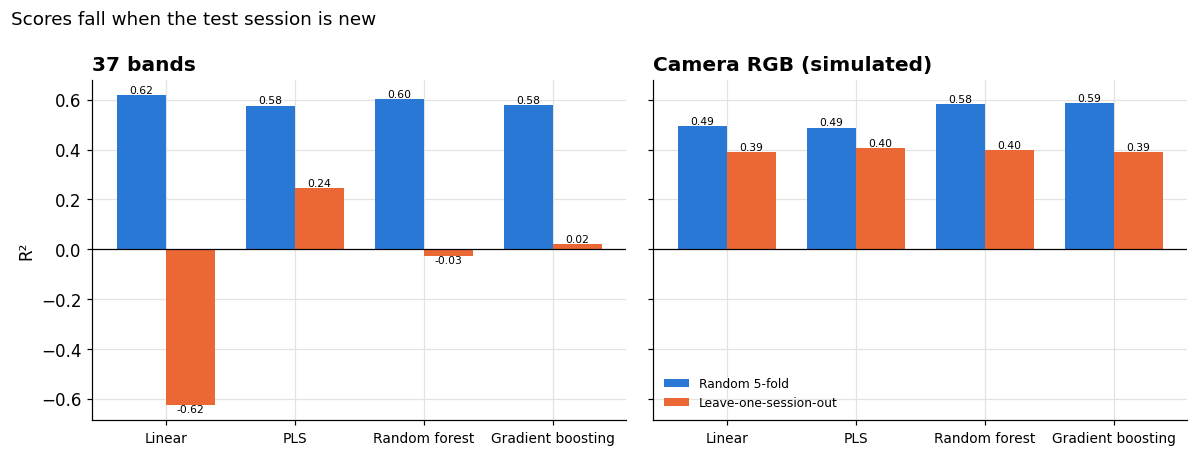

In [ ]:
# Figure 6: all four models, random test vs new session
for fname, key in [("RGB", "Camera RGB"), ("37 bands", "37 bands")]:
    for test in CV: rob[(fname, "Linear", test)] = r2_score(y, preds[(key, test)])
mods = ["Linear", "PLS", "Random forest", "Gradient boosting"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, fname, title in [(axes[0], "37 bands", "37 bands"), (axes[1], "RGB", "Camera RGB (simulated)")]:
    xs = np.arange(len(mods))
    for k, (test, col) in enumerate([("A random", "#2a78d6"), ("B new session", "#eb6834")]):
        vals = [rob[(fname, m, test)] for m in mods]
        bars = ax.bar(xs + (k - 0.5) * 0.38, vals, 0.38, color=col, label="Random 5-fold" if k == 0 else "Leave-one-session-out")
        ax.bar_label(bars, fmt="%.2f", fontsize=7)
    ax.axhline(0, color="k", lw=0.8); ax.set_xticks(xs, mods, fontsize=9); ax.set_title(title, loc="left")
axes[0].set_ylabel("R²"); axes[1].legend(frameon=False, fontsize=8)
fig.suptitle("Scores fall when the test session is new", x=0.01, ha="left", fontsize=12)
fig.tight_layout(); fig.savefig(f"{OUT}/fig6_model_comparison.png"); plt.show()

**Observation:** Every model drops on a new session, the 37-band models drop the most.

**Interpretation:** No the core conclusion does not depend on model choice because every single model family drops in performance when tested on new photo session. This universal performance drop proves that session-specific overfitting is a fundamental data-level problem rather than a limitation of any specific algorithm.

In [ ]:
# Can colour identify the photo session within one variety?
for v in ["Crimson", "Itum5", "AutumRoyal"]:
    s = df[df.variety == v]
    acc = cross_val_score(RandomForestClassifier(300, random_state=SEED), s[BANDS], s.session,
                          cv=StratifiedKFold(5, shuffle=True, random_state=SEED)).mean()
    print(f"{v:10s} {s.session.nunique()} sessions: {acc:.0%} correct (chance {s.session.value_counts(normalize=True).max():.0%})")

Crimson    4 sessions: 100% correct (chance 25%)
Itum5      5 sessions: 96% correct (chance 20%)
AutumRoyal 2 sessions: 100% correct (chance 51%)


**Observation:** Colour identifies the photo session with 96-100% accuracy.

**Interpretation:** This high classification accuracy proves that each photo session possesses a unique, dominant spectral or color signature caused by transient environmental conditions like lighting and background variations. Because of these non-chemical artificats are so distinct, models can easily learn to recognize specific sessions and associate their unique signatures with average pigment values instead of learning generalizable biochemical features.

In [ ]:
# RGB from all 28 cameras (PLS, 3 components, Test B). Needs camspec_database.txt in the repository.
path = "camspec_database.txt"
for url in [GH + path, "https://zenodo.org/records/3245883/files/camspec_database.txt?download=1"]:
    if os.path.exists(path): break
    try: urllib.request.urlretrieve(url, path)
    except Exception: pass
if os.path.exists(path):
    lines = [l for l in open(path).read().splitlines() if l.strip()]
    cams = {lines[i].strip(): [np.array(lines[i + k].split(), float) for k in (1, 2, 3)] for i in range(0, len(lines), 4)}
    sweep = {}
    for cname, curves in cams.items():
        Sc = np.vstack([np.interp(wl, cam_wl, c) for c in curves]); Xc = to_rgb(df[BANDS[:12]].values, Sc)
        p = cross_val_predict(make_pipeline(StandardScaler(), PLSRegression(3)), Xc, y, cv=LeaveOneGroupOut(), groups=day)
        sweep[cname] = r2_score(y, np.ravel(p))
    sweep = pd.Series(sweep).sort_values()
    print(f"{len(sweep)} cameras: R² {sweep.min():.2f} to {sweep.max():.2f}")
else:
    print("camspec_database.txt not found: upload it to the repository to run the camera sweep.")

28 cameras: R² 0.38 to 0.40


**Observation:** All 28 cameras give R² 0.38–0.40.

**Interpretation:** The camera hardware is not a bottleneck, as all 28 simulated models yield nearly identical R² scores (0.38 to 0.40). Instead, the true bottleneck is the environmental vairability of the photo-sessions specifically, uncalibrated day-to-day changes in ambient lighting and background conditions.

## Part G · KPI check (Report Section 6, Table 5)

In [ ]:
r = lambda f, t: r2_score(y, preds[(f, t)])
rgbA, rgbB, b37A, b37B = r("Camera RGB", "A random"), r("Camera RGB", "B new session"), r("37 bands", "A random"), r("37 bands", "B new session")
mae_rgbB = mean_absolute_error(y, preds[("Camera RGB", "B new session")])
mae_base = mean_absolute_error(y, cross_val_predict(lin(), np.zeros((len(y), 1)), y, cv=LeaveOneGroupOut(), groups=day))
ari_s, ari_v = adjusted_rand_score(day, km13), adjusted_rand_score(df.variety, km13)
kpi = pd.DataFrame([
    ["O1 R² on new session", "≥ 0.50", f"{rgbB:.2f} (RGB); {b37B:.2f} (37 bands)", rgbB >= 0.50],
    ["O1 MAE vs baseline", f"< {mae_base:.2f} mg/kg", f"{mae_rgbB:.2f} (RGB)", mae_rgbB < mae_base],
    ["O2 RGB vs 37 bands (new session)", "≥ 70 % of 37-band R²", f"{rgbB:.2f} vs {b37B:.2f}", rgbB >= 0.7 * b37B],
    ["O3 R² drop A → B", "≤ 0.10", f"{rgbA - rgbB:.2f} (RGB); {b37A - b37B:.2f} (37 bands)", (rgbA - rgbB) <= 0.10],
    ["O3 Clusters follow variety", "ARI variety > ARI session", f"{ari_v:.2f} vs {ari_s:.2f}", ari_v > ari_s],
    ["O4 Reproducible", "Yes", "Runs from public URLs, seed 42", True]],
    columns=["KPI", "Target", "Result", "Met?"])
kpi["Met?"] = kpi["Met?"].map({True: "Yes", False: "No"})
print(f"KPIs met: {(kpi['Met?'] == 'Yes').sum()} of {len(kpi)}"); kpi

KPIs met: 3 of 6


,KPI,Target,Result,Met?
0,O1 R² on new session,≥ 0.50,0.39 (RGB); -0.62 (37 bands),No
1,O1 MAE vs baseline,< 9.47 mg/kg,7.00 (RGB),Yes
2,O2 RGB vs 37 bands (new session),≥ 70 % of 37-band R²,0.39 vs -0.62,Yes
3,O3 R² drop A → B,≤ 0.10,0.11 (RGB); 1.24 (37 bands),No
4,O3 Clusters follow variety,ARI variety > ARI session,0.26 vs 0.74,No
5,O4 Reproducible,Yes,"Runs from public URLs, seed 42",Yes


The objectives for baseline improvment (O1 MAE) and keeping RGB comparable to the full 37 bands (O2) were successfully met. However, the model failed targets for absolute new-session performance (O1 R² ≥ 0.50), model stability (O3 R² drop), and cluster alignment (O3 ARI), because session-specific environmental features (like lighting) heavily confound the true pigment signal and fail to generalize.

In [ ]:
# Export the main tables for the repository
table4.round(3).to_csv(f"{OUT}/table4_main_model.csv"); kpi.to_csv(f"{OUT}/table5_kpi.csv", index=False)
pd.Series(rob).unstack().round(3).to_csv(f"{OUT}/robustness_models.csv")
print("Saved to", OUT, ":", sorted(os.listdir(OUT)))

Saved to outputs : ['fig0_workflow.png', 'fig1_tac_by_variety.png', 'fig2_band_correlation.png', 'fig3_pca_variety_session.png', 'fig5_pred_vs_measured_linear.png', 'fig6_model_comparison.png', 'robustness_models.csv', 'table4_main_model.csv', 'table5_kpi.csv']


Part H · Project status and link to the thesis to see which steps are done, which are being improved, and which are blocked:

| Step | Status | Link to findings / blocker |
|---|---|---|
| Grape-proxy pipeline and thesis validation design (unseen-day test, crossed capture) | Done | Parts A–G of this notebook; photo-day fingerprint (ARI 0.74) |
| Phone capture set-up with colour card, 2–3 phones, 3–4 days | In progress | The photo day swamped the pigment signal |
| Ube powder adulteration series (0–100 % purple sweet potato) | In progress | Spread target; the grape model only learned "purple or not" |
| Colour-card correction; offline Edge AI app | Planned | RGB with a linear model was enough for a small on-device model |
| pH-differential TAC on ube; thesis scope approval | Blocked | Lab (UV-Vis) access and supervisor confirmation pending |
| Philippine samples; Bohol Ubi Kinampay authentication | Blocked (For Future work) | EU import rules for fresh tubers; harvest risk mitigation; Bohol Ubi Kinampay GI application pending |

This mini-project proved that uncalibrated camera models primarily overfit to transient, session-specific environmental features like ambiennt lighting (reconstructed with 96-100% accuracy) rather than tracking actual chemical variations within variety classes. Consequently, stnadard random validation splits dramatically overestimate model performance, whereas validation on unseen capture sessions reveals a complete lack of predictive power inside uniform color classes. To resolve this bottleneck, my master's thesis experiment must incorporate physical color-card calibration targets across all sessions and deliberately collect samples over multiple days, using smartphones, to force the machine learning model to learn genuine chemical indicators instead of situational lighting footprints.